In [279]:
print('In the name of Allah')

In the name of Allah


In [280]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Problem 1:
Scenario:

A data scientist writes the following code:

from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')

imputer = SimpleImputer(strategy='median')

df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])

X = df.drop('Target', axis=1)

y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


Question: Identify the data leakage issue. Explain why it is wrong and write the corrected code.


In [281]:
df = pd.read_csv('data.csv')
df

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target
0,40.0,9165.0,55361,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,0,280.32
1,33.0,5522.0,48717,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,1,314.83
2,42.0,50589.0,64787,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,0,252.43
3,53.0,61289.0,80106,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,0,239.21
4,32.0,1604.0,31872,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,0,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253,3.2,82289.0,4.0,NaN,1832,17.0,Dhaka,A,C,Type1,NaN,C,Female,0,309.92
996,56.0,11596.0,41951,2.7,32733.0,2.0,NaN,1127,17.0,Sylhet,A,C,Type1,Cabin_D,S,Male,0,222.41
997,42.0,NaN,44369,2.6,50537.0,2.0,346644.0,1654,24.7,Rajshahi,C,B,Type2,NaN,S,Female,0,221.89
998,NaN,276.0,52691,3.9,143880.0,4.0,307904.0,1908,Unknown,Rajshahi,B,B,NaN,NaN,Q,Female,0,293.69


In [282]:
imputer = SimpleImputer(strategy='median')
df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])
X = df.drop('Target', axis=1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)



> imputer.fit_transform(df[['Age', 'Salary']])



The imputer is being fitted on the entire dataset before train-test split.

This means the imputer learns the median values using both:

1. Training data
2. Test data

So, information from the test set leaks into the training process.

## Why is this wrong?

The test set should remain completely unseen during preprocessing and training.

When the imputer calculates the median using the full dataset, the model indirectly gains knowledge about the test data distribution. This can produce unrealistically good model performance.

In [283]:
df.isnull().sum()

,0
Age,0
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,50
City,50


In [284]:
X = df.drop(['Target'], axis = 1)

X

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
0,40.0,9165.0,55361.0,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,280.32
1,33.0,5522.0,48717.0,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,314.83
2,42.0,50589.0,64787.0,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,252.43
3,53.0,61289.0,80106.0,3.6,107581.0,1.0,359753.0,2075,22.7,Rajshahi,C,B,Type2,NaN,S,Female,239.21
4,32.0,1604.0,31872.0,4.0,89654.0,1.0,228869.0,1248,NaN,Rajshahi,A,C,Type2,NaN,S,Female,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253.0,3.2,82289.0,4.0,NaN,1832,17.0,Dhaka,A,C,Type1,NaN,C,Female,309.92
996,56.0,11596.0,41951.0,2.7,32733.0,2.0,NaN,1127,17.0,Sylhet,A,C,Type1,Cabin_D,S,Male,222.41
997,42.0,NaN,44369.0,2.6,50537.0,2.0,346644.0,1654,24.7,Rajshahi,C,B,Type2,NaN,S,Female,221.89
998,34.5,276.0,52691.0,3.9,143880.0,4.0,307904.0,1908,Unknown,Rajshahi,B,B,NaN,NaN,Q,Female,293.69


In [285]:
y = df['Target']

y

,Target
0,0
1,1
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [286]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [287]:
X_train
display(y_train)

,Target
29,0
535,0
695,0
557,0
836,0
...,...
106,0
270,0
860,0
435,0


In [288]:
X_test
display(y_test)

,Target
521,0
737,0
740,0
660,0
411,0
...,...
408,0
332,0
208,0
613,0


In [289]:
X_train.isnull().sum()

,0
Age,0
Income,126
Salary,0
Rating,66
Annual_Income,97
Customer_Support_Calls,62
House_Price,83
Square_Feet,0
Temperature,42
City,38


In [290]:
imputer = SimpleImputer(strategy='median')

In [291]:
X_train[['Age', 'Salary']] = imputer.fit_transform(X_train[['Age', 'Salary']])

X_test[['Age', 'Salary']] = imputer.transform(X_test[['Age', 'Salary']])

In [292]:
# Final version

X = df.drop(['Target'], axis = 1)
y = df['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
X_train.isnull().sum()
imputer = SimpleImputer(strategy='median')
X_train[['Age', 'Salary']] = imputer.fit_transform(X_train[['Age', 'Salary']])

X_test[['Age', 'Salary']] = imputer.transform(X_test[['Age', 'Salary']])

# Problem 2:

Question: Using the provided data.csv file, write code to find:

Total missing values in each column

Percentage of missing values per column

Which columns have more than 50% missing values?


In [293]:
missing_values = df.isnull().sum()

print(f'Total missing values in each column : \n{missing_values}')

missing_percentage = ( missing_values / len(df) ) * 100

print(f'Percentage of Missing Values Per Column : \n{missing_percentage}')

more_than_50 = missing_percentage[missing_percentage > 50]

print(f'Columns with More Than 50% Missing Values :\n{more_than_50}')

Total missing values in each column : 
Age                         0
Income                    150
Salary                      0
Rating                     80
Annual_Income             120
Customer_Support_Calls     80
House_Price               100
Square_Feet                 0
Temperature                50
City                       50
Product_Type                0
Location                    0
Diagnosis                 220
Cabin                     680
Embarked                    2
Gender                      0
Target                      0
Price_Target                0
dtype: int64
Percentage of Missing Values Per Column : 
Age                        0.0
Income                    15.0
Salary                     0.0
Rating                     8.0
Annual_Income             12.0
Customer_Support_Calls     8.0
House_Price               10.0
Square_Feet                0.0
Temperature                5.0
City                       5.0
Product_Type               0.0
Location                

# Problem 3:

Question: Look at the Temperature column in data.csv. It contains:

Numeric values like 22.5, 18.6

String 'Unknown'

NaN values

Write code to handle this column properly before imputation.


In [294]:
df['Temperature'].isnull().sum()
df['Temperature'].sample(10)

,Temperature
757,Unknown
830,Unknown
667,21.0
712,2.9
910,22.8
905,21.3
487,21.9
209,12.9
789,23.8
503,NaN


In [295]:
df['Temperature'] = df['Temperature'].replace('Unknown', np.nan)

df['Temperature'].sample(10)
df['Temperature'].isnull().sum()

np.int64(115)

In [296]:
df['Temperature'] = pd.to_numeric(df['Temperature'], errors = 'coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1000 non-null   float64
 1   Income                  850 non-null    float64
 2   Salary                  1000 non-null   float64
 3   Rating                  920 non-null    float64
 4   Annual_Income           880 non-null    float64
 5   Customer_Support_Calls  920 non-null    float64
 6   House_Price             900 non-null    float64
 7   Square_Feet             1000 non-null   int64  
 8   Temperature             885 non-null    float64
 9   City                    950 non-null    object 
 10  Product_Type            1000 non-null   object 
 11  Location                1000 non-null   object 
 12  Diagnosis               780 non-null    object 
 13  Cabin                   320 non-null    object 
 14  Embarked                998 non-null    o

In [297]:
df['Temperature'].isnull().sum()

np.int64(115)

In [298]:
# mean impute

temperature_mean = df['Temperature'].mean()
temperature_mean

np.float64(22.46960451977401)

In [299]:
# median impute

temperature_median = df['Temperature'].median()
temperature_median

22.6

In [300]:
df['temperature_median_imputer'] = df['Temperature'].fillna(temperature_median)

df['temperature_mean_imputer'] = df['Temperature'].fillna(temperature_mean)

In [301]:
df[['temperature_median_imputer', 'temperature_mean_imputer']].sample(10)

,temperature_median_imputer,temperature_mean_imputer
561,22.6,22.469605
297,22.6,22.469605
394,19.4,19.400000
226,23.5,23.500000
808,24.1,24.100000
933,23.5,23.500000
536,23.0,23.000000
446,31.7,31.700000
274,22.6,22.469605
985,23.1,23.100000


<Axes: xlabel='temperature_median_imputer', ylabel='Density'>

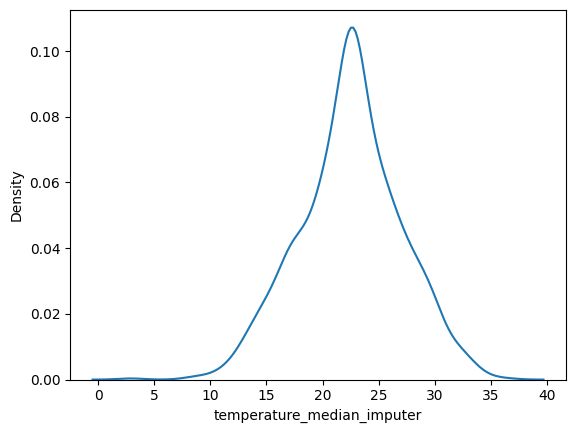

In [302]:
sns.kdeplot(data = df, x = 'temperature_median_imputer')

<Axes: xlabel='temperature_mean_imputer', ylabel='Density'>

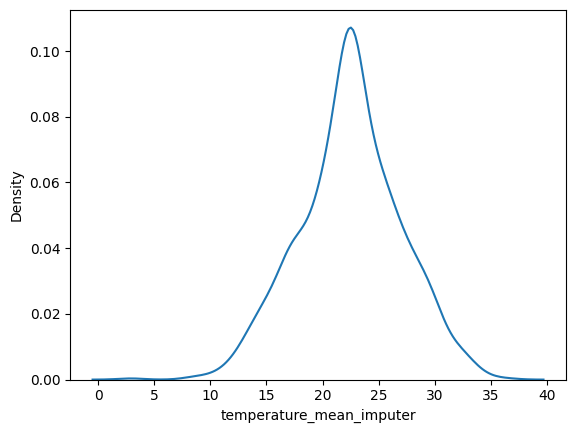

In [303]:
sns.kdeplot(data = df, x = 'temperature_mean_imputer')

In [304]:
temperature_imputer = SimpleImputer(missing_values = np.nan, strategy = 'mean')

temperature_imputer.fit(df[['Temperature']])

df['Temperature'] = temperature_imputer.transform(df[['Temperature']]).ravel()

In [305]:
df['Temperature'].sample(10)
df.drop(['temperature_median_imputer', 'temperature_mean_imputer'], axis = 1, inplace = True)
df

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target
0,40.0,9165.0,55361.0,2.9,NaN,NaN,495310.0,2091,15.100000,Dhaka,Unknown,A,NaN,NaN,S,Male,0,280.32
1,33.0,5522.0,48717.0,NaN,52868.0,1.0,368695.0,1504,28.300000,Chittagong,C,C,Type3,NaN,S,Female,1,314.83
2,42.0,50589.0,64787.0,3.1,79526.0,2.0,453606.0,2052,22.000000,Sylhet,A,C,Type1,NaN,C,Female,0,252.43
3,53.0,61289.0,80106.0,3.6,107581.0,1.0,359753.0,2075,22.700000,Rajshahi,C,B,Type2,NaN,S,Female,0,239.21
4,32.0,1604.0,31872.0,4.0,89654.0,1.0,228869.0,1248,22.469605,Rajshahi,A,C,Type2,NaN,S,Female,0,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253.0,3.2,82289.0,4.0,NaN,1832,17.000000,Dhaka,A,C,Type1,NaN,C,Female,0,309.92
996,56.0,11596.0,41951.0,2.7,32733.0,2.0,NaN,1127,17.000000,Sylhet,A,C,Type1,Cabin_D,S,Male,0,222.41
997,42.0,NaN,44369.0,2.6,50537.0,2.0,346644.0,1654,24.700000,Rajshahi,C,B,Type2,NaN,S,Female,0,221.89
998,34.5,276.0,52691.0,3.9,143880.0,4.0,307904.0,1908,22.469605,Rajshahi,B,B,NaN,NaN,Q,Female,0,293.69


In [306]:
df['Temperature'].sample(10)

,Temperature
419,30.500000
865,27.700000
821,31.100000
250,23.600000
946,28.500000
400,27.700000
651,17.100000
71,27.500000
960,22.469605
77,19.800000


In [307]:
# Final Answer

# Step 1: Replace invalid strings
df['Temperature'] = df['Temperature'].replace('Unknown', np.nan)

# Step 2: Convert to numeric
df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')

# Step 3: Impute using median
imputer = SimpleImputer(strategy='median')
df['Temperature'] = imputer.fit_transform(df[['Temperature']])

# Problem 4:

Question: For the Diagnosis column in data.csv, implement imputation with:

Constant strategy using 'Missing' string

Add a missing indicator column

Write the complete code using SimpleImputer.


In [308]:
df.isnull().sum()

,0
Age,0
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,0
City,50


In [309]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1000 non-null   float64
 1   Income                  850 non-null    float64
 2   Salary                  1000 non-null   float64
 3   Rating                  920 non-null    float64
 4   Annual_Income           880 non-null    float64
 5   Customer_Support_Calls  920 non-null    float64
 6   House_Price             900 non-null    float64
 7   Square_Feet             1000 non-null   int64  
 8   Temperature             1000 non-null   float64
 9   City                    950 non-null    object 
 10  Product_Type            1000 non-null   object 
 11  Location                1000 non-null   object 
 12  Diagnosis               780 non-null    object 
 13  Cabin                   320 non-null    object 
 14  Embarked                998 non-null    o

In [310]:
df['Diagnosis'].sample(10)

,Diagnosis
143,NaN
365,Type1
3,Type2
816,Type1
382,Type1
292,NaN
888,NaN
323,Type1
502,Type2
329,Type3


In [311]:
diagnosis_imputer = SimpleImputer(missing_values = np.nan, strategy = 'most_frequent')

diagnosis_imputer.fit(df[['Diagnosis']])

df['Diagnosis'] = diagnosis_imputer.transform(df[['Diagnosis']]).ravel()

In [312]:
df.isnull().sum()

,0
Age,0
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,0
City,50


# Problem 5:

Question: Using the Age column from data.csv:

Calculate mean and median from training data only

Create two new columns: Age_mean_imputed and Age_median_imputed

Plot KDE for both to compare distributions

Which one would you choose and why?


In [313]:
df.isnull().sum()

,0
Age,0
Income,150
Salary,0
Rating,80
Annual_Income,120
Customer_Support_Calls,80
House_Price,100
Square_Feet,0
Temperature,0
City,50


In [314]:
df['Age'].isnull().sum()

np.int64(0)

In [315]:
X = df.drop(['Target'], axis = 1) # Feature

X

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
0,40.0,9165.0,55361.0,2.9,NaN,NaN,495310.0,2091,15.100000,Dhaka,Unknown,A,Type1,NaN,S,Male,280.32
1,33.0,5522.0,48717.0,NaN,52868.0,1.0,368695.0,1504,28.300000,Chittagong,C,C,Type3,NaN,S,Female,314.83
2,42.0,50589.0,64787.0,3.1,79526.0,2.0,453606.0,2052,22.000000,Sylhet,A,C,Type1,NaN,C,Female,252.43
3,53.0,61289.0,80106.0,3.6,107581.0,1.0,359753.0,2075,22.700000,Rajshahi,C,B,Type2,NaN,S,Female,239.21
4,32.0,1604.0,31872.0,4.0,89654.0,1.0,228869.0,1248,22.469605,Rajshahi,A,C,Type2,NaN,S,Female,179.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,31.0,16472.0,50253.0,3.2,82289.0,4.0,NaN,1832,17.000000,Dhaka,A,C,Type1,NaN,C,Female,309.92
996,56.0,11596.0,41951.0,2.7,32733.0,2.0,NaN,1127,17.000000,Sylhet,A,C,Type1,Cabin_D,S,Male,222.41
997,42.0,NaN,44369.0,2.6,50537.0,2.0,346644.0,1654,24.700000,Rajshahi,C,B,Type2,NaN,S,Female,221.89
998,34.5,276.0,52691.0,3.9,143880.0,4.0,307904.0,1908,22.469605,Rajshahi,B,B,Type1,NaN,Q,Female,293.69


In [316]:
y = df['Target'] # Target Column

y

,Target
0,0
1,1
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [317]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [318]:
X_train

display(y_train)

,Target
29,0
535,0
695,0
557,0
836,0
...,...
106,0
270,0
860,0
435,0


In [319]:
X_test

display(y_test)

,Target
521,0
737,0
740,0
660,0
411,0
...,...
408,0
332,0
208,0
613,0


In [320]:
X_train.isnull().sum()

,0
Age,0
Income,126
Salary,0
Rating,66
Annual_Income,97
Customer_Support_Calls,62
House_Price,83
Square_Feet,0
Temperature,0
City,38


In [321]:
X_test.isnull().sum()

,0
Age,0
Income,24
Salary,0
Rating,14
Annual_Income,23
Customer_Support_Calls,18
House_Price,17
Square_Feet,0
Temperature,0
City,12


In [322]:
# mean impute

age_mean = X_train['Age'].mean()

age_mean

np.float64(34.610625)

In [323]:
# median impute

age_median = X_train['Age'].median()

age_median

34.5

In [324]:
X_train['age_mean_imputer'] = X_train['Age'].fillna(age_mean)

X_test['age_mean_imputer'] = X_test['Age'].fillna(age_mean)


X_train['age_median_imputer'] = X_train['Age'].fillna(age_median)

X_test['age_median_imputer'] = X_test['Age'].fillna(age_median)

In [325]:
X_train

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target,age_mean_imputer,age_median_imputer
29,34.5,20541.0,46632.0,4.2,30172.0,1.0,111387.0,1866,32.5,Chittagong,B,B,Type1,NaN,S,Male,231.94,34.5,34.5
535,35.0,46050.0,71684.0,2.8,72318.0,2.0,289801.0,2067,28.2,Dhaka,B,B,Type1,NaN,Q,Female,228.30,35.0,35.0
695,31.0,8652.0,85790.0,1.4,NaN,4.0,227513.0,1812,24.2,NaN,C,C,Type1,NaN,C,Male,266.84,31.0,31.0
557,29.0,93707.0,52109.0,4.5,100627.0,1.0,191999.0,1510,24.5,Dhaka,A,B,Type1,NaN,S,Female,221.75,29.0,29.0
836,53.0,41021.0,61257.0,1.9,52816.0,1.0,106457.0,1438,21.8,Sylhet,B,C,Type1,NaN,S,Female,261.28,53.0,53.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,57.0,1868.0,53454.0,4.1,55001.0,3.0,NaN,1115,27.2,Chittagong,A,A,Type1,NaN,S,Female,161.48,57.0,57.0
270,52.0,55063.0,52856.0,3.1,111554.0,2.0,162436.0,2028,23.6,Sylhet,B,A,Type1,NaN,C,Female,303.58,52.0,52.0
860,37.0,7655.0,54442.0,3.7,40181.0,5.0,231088.0,1142,21.6,Chittagong,Unknown,A,Type1,NaN,S,Female,327.19,37.0,37.0
435,35.0,48894.0,50286.0,4.1,96119.0,3.0,NaN,1722,24.5,Chittagong,A,A,Type2,NaN,S,Male,311.50,35.0,35.0


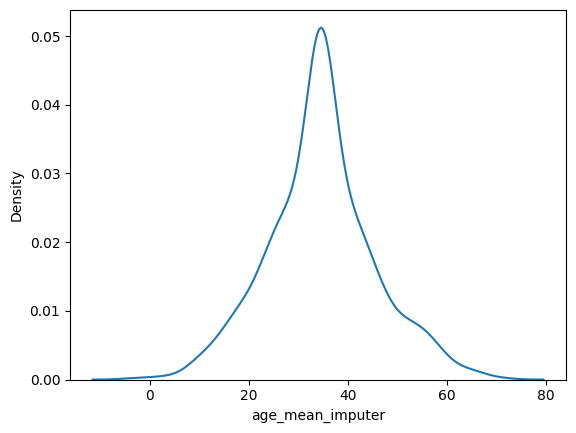

In [326]:
sns.kdeplot(data = X_train, x = 'age_mean_imputer')

plt.show()

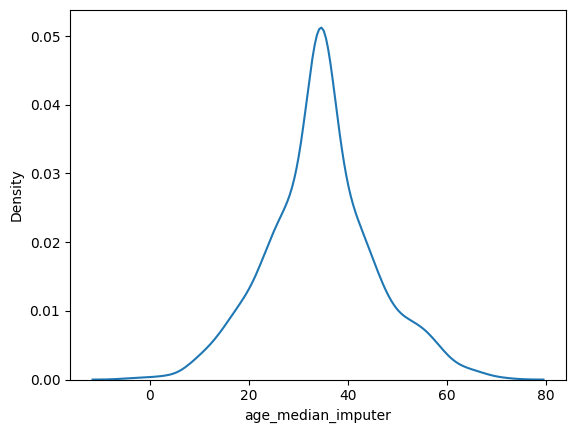

In [327]:
sns.kdeplot(data = X_train, x = 'age_median_imputer')

plt.show()

In [328]:
skew_value = X_train['Age'].skew()

skew_value

np.float64(0.1290033665995715)

Imputation Choice & Justification
Choice: Mean Imputation

Why:

Near-Symmetric Distribution: The Age column has a very low skewness of 0.129, indicating the data is well-balanced and lacks significant outliers that would pull the mean away from the center.

Similarity of Values: Because the distribution is nearly symmetric, the Mean (34.63) and Median (34.00) are almost identical. This means both methods have a nearly identical impact on the dataset's distribution.

Standard Practice: Mean imputation is the standard approach for normally distributed or symmetric data, while median imputation is typically reserved for cases with high skewness or extreme outliers.

In [329]:
age_imputer = SimpleImputer(missing_values = np.nan, strategy = 'mean')

age_imputer.fit(X_train[['Age']])

X_train['Age'] = age_imputer.transform(X_train[['Age']]).ravel()

In [330]:
X_train.isnull().sum()

X_train.drop(['age_mean_imputer', 'age_median_imputer'], axis = 1, inplace = True)


In [346]:
X_train.sample(10)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Price_Target
69,34.5,NaN,49940.0,3.1,NaN,3.0,362490.0,1526,18.400000,Khulna,A,B,Type1,NaN,S,Male,215.83
780,37.0,NaN,45062.0,NaN,NaN,NaN,272404.0,2710,17.500000,Chittagong,B,A,Type2,NaN,S,Male,233.71
841,43.0,65744.0,70468.0,4.1,56675.0,1.0,251432.0,2311,27.200000,Chittagong,B,B,Type3,NaN,C,Female,276.06
297,38.0,5496.0,25557.0,2.6,27208.0,2.0,386406.0,2477,22.469605,Dhaka,A,C,Type2,Cabin_A,S,Female,273.86
846,38.0,NaN,62959.0,3.3,NaN,3.0,411263.0,1788,27.400000,Dhaka,B,A,Type2,Cabin_B,Q,Male,239.05
28,27.0,186205.0,55972.0,5.0,43387.0,4.0,313807.0,1007,32.700000,Rajshahi,C,C,Type1,NaN,Q,Female,195.20
236,10.0,62965.0,80409.0,3.2,28703.0,4.0,312224.0,2441,32.300000,Khulna,C,A,Type3,NaN,C,Female,293.06
961,50.0,28143.0,42734.0,3.6,47846.0,1.0,397784.0,2332,31.500000,Dhaka,B,C,Type2,Cabin_G,C,Male,228.92
406,22.0,18684.0,90364.0,5.3,107102.0,1.0,511129.0,2494,25.200000,Dhaka,B,C,Type3,NaN,C,Male,237.47
492,35.0,NaN,69994.0,3.6,73296.0,2.0,334210.0,1335,24.300000,Dhaka,A,C,Type1,NaN,C,Male,208.42


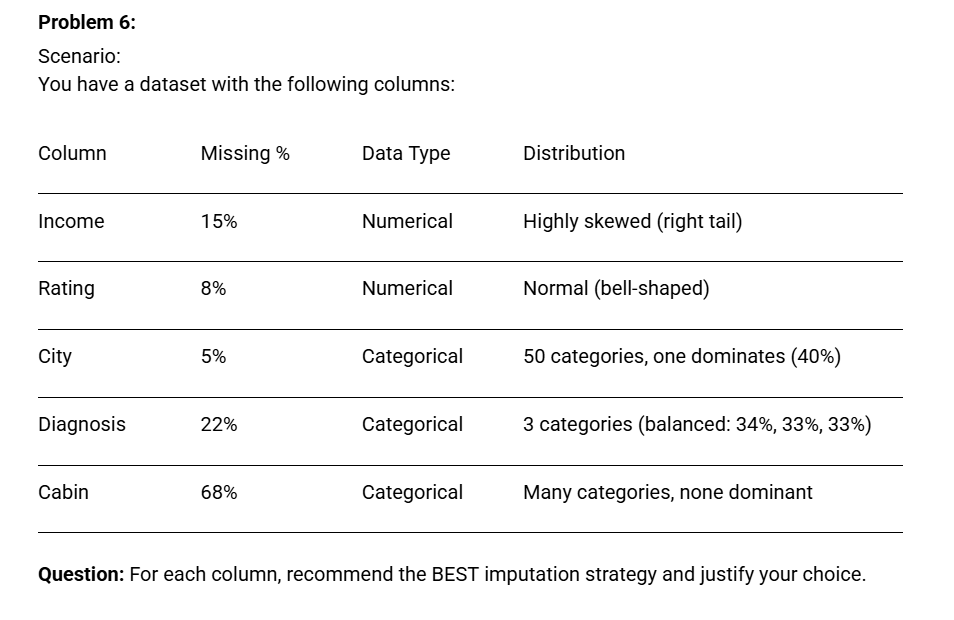

For the **Income** column, we can see that 15% of the values are missing and the distribution is highly skewed. In this case, we should use the **median** for imputation instead of the mean, as it is more robust against the right-tail skew.

For the **Rating** column, which has 8% missing numerical data and a normal distribution, either the **mean** or the median would work effectively.

Moving on to the **City** column, there is a 5% missing rate in a categorical feature where one specific category dominates at 40%. For this scenario, the best strategy is **'most_frequent'** (mode) imputation.

In the **Diagnosis** column, where 22% of the values are missing and the three categories are almost perfectly balanced (around 33-34% each), the best approach is to use a **constant** value (like "Unknown") to avoid biasing the balance.

Finally, for the **Cabin** column, the image shows a missing rate of 68%. Given such a high percentage of missing data in a categorical column with no dominant class, the best option is to **drop the column** entirely.